In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error

In [2]:
# 1. LOAD DATASET (Titanic)
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Data Preprocessing
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Fare'] = df['Fare'].fillna(df['Fare'].median())
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

# Feature Selection
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']
X = df[features]
y_classification = df['Survived']
y_regression = df['Fare']

In [3]:
# PART A: DECISION TREE CLASSIFIER (Predicting Survival)

# 1. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y_classification, test_size=0.2, random_state=42)

# 2. Model Training
clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X_train, y_train)

# 3. Model Evaluation
y_pred_clf = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred_clf)
cm = confusion_matrix(y_test, y_pred_clf)

print("=== DECISION TREE CLASSIFIER RESULTS ===")
print(f"Accuracy Score: {acc * 100:.2f}%\n")
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_clf))

=== DECISION TREE CLASSIFIER RESULTS ===
Accuracy Score: 79.89%

Confusion Matrix:
[[92 13]
 [23 51]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.88      0.84       105
           1       0.80      0.69      0.74        74

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



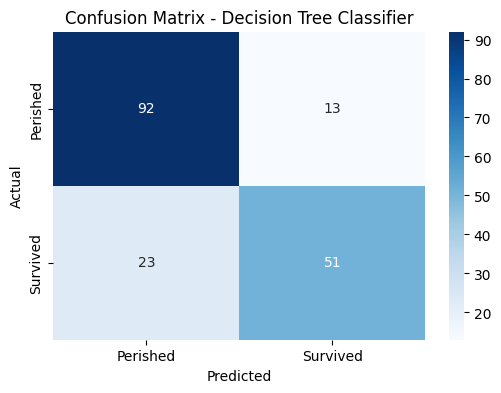

In [4]:
# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Perished', 'Survived'], yticklabels=['Perished', 'Survived'])
plt.title('Confusion Matrix - Decision Tree Classifier')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [5]:
# PART B: LINEAR REGRESSION (Predicting House/Ticket Price)

X_reg = df[['Pclass', 'Age', 'SibSp', 'Parch']]
y_reg = df['Fare']

# 1. Train/Test Split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# 2. Model Training
reg = LinearRegression()
reg.fit(X_train_reg, y_train_reg)

# 3. Model Evaluation (MSE)
y_pred_reg = reg.predict(X_test_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)

print("\n=== LINEAR REGRESSION RESULTS ===")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.2f}")


=== LINEAR REGRESSION RESULTS ===
Mean Squared Error (MSE): 946.34
Root Mean Squared Error (RMSE): 30.76
